# Лаба 4. Вероятностные тесты простоты

Реализованы три теста: **Ферма**, **Соловея — Штрассена** и **Миллера — Рабина**. Каждый тест для одного основания $a\in\{1,\dots,N-1\}$ даёт один из двух ответов:

* «$N$ — составное» — это доказано (найден свидетель непростоты);
* «неизвестно» — $N$ простое, либо $a$ — «лжец» для составного $N$.

| Тест | Условие простоты | Вероятность ответа «составное» для составного $N$ за один раунд |
|---|---|---|
| Ферма | $a^{N-1}\equiv1 \pmod N$ | не гарантирована (числа Кармайкла: $P_0=1-\varphi(N)/(N-1)$) |
| Соловей — Штрассен | $a^{(N-1)/2}\equiv\left(\frac aN\right)\pmod N$ | не менее $1/2$ |
| Миллер — Рабин | $r_0=1$ или $r_k=-1$, $r_k=a^{2^ku}$, $N-1=2^tu$ | не менее $3/4$ |

После $s$ раундов вероятность не обнаружить составность не превосходит $(1-P_0)^s$.

### Подготовка (для Google Colab)
Ноутбук импортирует `primality.py`. При локальном запуске из папки лабы ячейка ничего не делает.
В Colab она клонирует репозиторий и находит модуль сама. Если клонировать не получилось (например, репозиторий приватный), предложит загрузить файл вручную.

In [1]:
import importlib, glob, os, subprocess, sys

REPO_URL = "https://github.com/KseniaKov/methods-programming_lab.git"   # пусто = сразу загрузить файл вручную
MODULE = "primality"

try:
    importlib.import_module(MODULE)
except ModuleNotFoundError:
    found = False
    if REPO_URL:
        try:
            subprocess.run(["git", "clone", "-q", REPO_URL, "repo"], check=True)
            paths = glob.glob(f"repo/**/{MODULE}.py", recursive=True)
            if paths:
                sys.path.append(os.path.dirname(os.path.abspath(paths[0])))
                found = True
        except (subprocess.CalledProcessError, FileNotFoundError):
            print("Не удалось клонировать репозиторий")
    if not found:
        from google.colab import files
        print(f"Выберите файл {MODULE}.py с компьютера")
        files.upload()
    importlib.invalidate_caches()
    importlib.import_module(MODULE)
print(f"{MODULE}.py найден")

primality.py найден


In [2]:
import random, time
from math import gcd
import matplotlib.pyplot as plt
from primality import (fermat_round, solovay_strassen_round, miller_rabin_round,
                       fermat_test, solovay_strassen_test, miller_rabin_test,
                       jacobi, mr_decompose, mr_sequence, liars)

def verdict(ok):                       # ответ теста по-русски
    return "неизвестно" if ok else "СОСТАВНОЕ"

def is_prime(n):                       # точная проверка простоты (для сравнения)
    return n > 1 and all(n % d for d in range(2, int(n ** 0.5) + 1))

def factorize(n):
    f, d = {}, 2
    while d * d <= n:
        while n % d == 0:
            f[d] = f.get(d, 0) + 1; n //= d
        d += 1
    if n > 1: f[n] = f.get(n, 0) + 1
    return f

def phi(n):
    r = n
    for p in factorize(n): r = r // p * (p - 1)
    return r

## 1. Тест Ферма по шагам
Для составного $N=91=7\cdot13$ и простого $97$. Столбец $d$ — шаг 1 ($d=(a,N)$), столбец $a^{N-1}$ — шаг 2.

In [3]:
for N in (91, 97):
    print(f"N = {N}")
    print("  a | d = (a,N) | a^(N-1) mod N | ответ")
    for a in (2, 3, 7, 10, 12, 22, 27):
        d = gcd(a, N)
        print(f"{a:3d} | {d:9d} | {pow(a, N - 1, N):13d} | {verdict(fermat_round(N, a))}")
    print()

N = 91
  a | d = (a,N) | a^(N-1) mod N | ответ
  2 |         1 |            64 | СОСТАВНОЕ
  3 |         1 |             1 | неизвестно
  7 |         7 |            77 | СОСТАВНОЕ
 10 |         1 |             1 | неизвестно
 12 |         1 |             1 | неизвестно
 22 |         1 |             1 | неизвестно
 27 |         1 |             1 | неизвестно

N = 97
  a | d = (a,N) | a^(N-1) mod N | ответ
  2 |         1 |             1 | неизвестно
  3 |         1 |             1 | неизвестно
  7 |         1 |             1 | неизвестно
 10 |         1 |             1 | неизвестно
 12 |         1 |             1 | неизвестно
 22 |         1 |             1 | неизвестно
 27 |         1 |             1 | неизвестно


## 2. Тест Соловея — Штрассена по шагам
Сравнивается $a^{(N-1)/2} \bmod N$ с символом Якоби $\left(\frac aN\right)$ (при $-1$ берём $N-1$).

In [4]:
for N in (91, 97):
    print(f"N = {N}")
    print("  a | d | (a/N) | a^((N-1)/2) mod N | ответ")
    for a in (2, 3, 7, 10, 12, 22, 27):
        d = gcd(a, N)
        print(f"{a:3d} | {d} | {jacobi(a, N):5d} | {pow(a, (N - 1) // 2, N):17d} | {verdict(solovay_strassen_round(N, a))}")
    print()

N = 91
  a | d | (a/N) | a^((N-1)/2) mod N | ответ
  2 | 1 |    -1 |                57 | СОСТАВНОЕ
  3 | 1 |    -1 |                27 | СОСТАВНОЕ
  7 | 7 |     0 |                21 | СОСТАВНОЕ
 10 | 1 |    -1 |                90 | неизвестно
 12 | 1 |    -1 |                90 | неизвестно
 22 | 1 |     1 |                 1 | неизвестно
 27 | 1 |    -1 |                27 | СОСТАВНОЕ

N = 97
  a | d | (a/N) | a^((N-1)/2) mod N | ответ
  2 | 1 |     1 |                 1 | неизвестно
  3 | 1 |     1 |                 1 | неизвестно
  7 | 1 |    -1 |                96 | неизвестно
 10 | 1 |    -1 |                96 | неизвестно
 12 | 1 |     1 |                 1 | неизвестно
 22 | 1 |     1 |                 1 | неизвестно
 27 | 1 |     1 |                 1 | неизвестно


## 3. Тест Миллера — Рабина по шагам
$N-1=2^t u$; считаем $r_k=a^{2^k u} \bmod N$ для $k=0,\dots,t-1$. Ответ «неизвестно», если $r_0=1$ или некоторое $r_k=N-1$.

In [5]:
for N, bases in ((561, (2, 5, 7)), (2047, (2, 3)), (97, (2, 3))):
    t, u = mr_decompose(N)
    print(f"N = {N}: N-1 = 2^{t} * {u}")
    for a in bases:
        print(f"   a = {a}: r_k = {mr_sequence(N, a)}  ->  {verdict(miller_rabin_round(N, a))}")

N = 561: N-1 = 2^4 * 35
   a = 2: r_k = [263, 166, 67, 1]  ->  СОСТАВНОЕ
   a = 5: r_k = [23, 529, 463, 67]  ->  СОСТАВНОЕ
   a = 7: r_k = [241, 298, 166, 67]  ->  СОСТАВНОЕ
N = 2047: N-1 = 2^1 * 1023
   a = 2: r_k = [1]  ->  неизвестно
   a = 3: r_k = [1565]  ->  СОСТАВНОЕ
N = 97: N-1 = 2^5 * 3
   a = 2: r_k = [8, 64, 22, 96, 1]  ->  неизвестно
   a = 3: r_k = [27, 50, 75, 96, 1]  ->  неизвестно


## 4. Сравнение с точной проверкой простоты
Прогоним все тесты для каждого $N<3000$ и сравним с точным ответом. С малым числом раундов $s$ возможны ошибки: составное число получает ответ «неизвестно». С ростом $s$ они исчезают.

In [6]:
for s in (3, 20):
    print(f"s = {s} раундов")
    for name, test in (("Ферма", fermat_test), ("Соловей-Штрассен", solovay_strassen_test),
                       ("Миллер-Рабин", miller_rabin_test)):
        rnd = random.Random(1)
        bad = [N for N in range(2, 3000) if test(N, s, rnd) != is_prime(N)]
        print(f"  {name:17s} ошибок: {len(bad)}  {bad}")

s = 3 раундов
  Ферма             ошибок: 3  [21, 561, 1105]
  Соловей-Штрассен  ошибок: 1  [21]
  Миллер-Рабин      ошибок: 1  [21]
s = 20 раундов
  Ферма             ошибок: 0  []
  Соловей-Штрассен  ошибок: 0  []
  Миллер-Рабин      ошибок: 0  []


## 5. Множества «лжецов» и границы из методички
Для составных нечётных $N\le1500$ переберём все основания и найдём долю «лжецов» среди чисел, взаимно простых с $N$ (элементов $\mathbb Z_N^*$). Теория: у Ферма (если $N$ не число Кармайкла) и у Соловея — Штрассена не более $1/2$, у Миллера — Рабина не более $1/4$ (для $N=9$ — исключение). Числа Кармайкла — те, для которых лжецами Ферма оказываются **все** взаимно простые основания.

числа Кармайкла среди нечётных составных N <= 1500: [561, 1105]

тест                           | макс. доля лжецов | при N | граница
Ферма (не Кармайкл)            |             0.500 |    15 | 1/2
Ферма (число Кармайкла)        |             1.000 |   561 | нет (1)
Соловей-Штрассен               |             0.250 |    15 | 1/2
Миллер-Рабин                   |             0.250 |    15 | 1/4

N = 9 (исключение): доля лжецов у Соловея-Штрассена и Миллера-Рабина равна 0.333 и 0.333


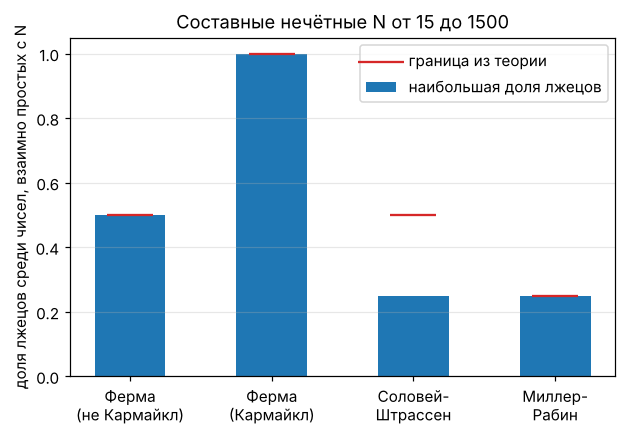

In [7]:
composites = [n for n in range(9, 1501, 2) if not is_prime(n)]
stats = {}      # название -> (максимальная доля, N)
for N in composites:
    ph = phi(N)
    for key, single in (("F", fermat_round), ("SS", solovay_strassen_round), ("MR", miller_rabin_round)):
        share = len(liars(N, single)) / ph
        name = key
        if key == "F":
            name = "F-Кармайкл" if len(liars(N, single)) == ph else "F"
        if N > 9 and (name not in stats or share > stats[name][0]):
            stats[name] = (share, N)

carm = [N for N in composites if len(liars(N, fermat_round)) == phi(N)]
print("числа Кармайкла среди нечётных составных N <= 1500:", carm)
print()
print("тест                           | макс. доля лжецов | при N | граница")
for name, label, bound in (("F", "Ферма (не Кармайкл)", "1/2"), ("F-Кармайкл", "Ферма (число Кармайкла)", "нет (1)"),
                           ("SS", "Соловей-Штрассен", "1/2"), ("MR", "Миллер-Рабин", "1/4")):
    share, N = stats[name]
    print(f"{label:30s} | {share:17.3f} | {N:5d} | {bound}")
print()
print("N = 9 (исключение): доля лжецов у Соловея-Штрассена и Миллера-Рабина равна",
      round(len(liars(9, solovay_strassen_round)) / phi(9), 3), "и",
      round(len(liars(9, miller_rabin_round)) / phi(9), 3))

labels = ["Ферма\n(не Кармайкл)", "Ферма\n(Кармайкл)", "Соловей-\nШтрассен", "Миллер-\nРабин"]
vals = [stats[k][0] for k in ("F", "F-Кармайкл", "SS", "MR")]
bounds = [0.5, 1.0, 0.5, 0.25]
plt.figure(figsize=(6.4, 4))
plt.bar(range(4), vals, width=0.5, label="наибольшая доля лжецов")
plt.scatter(range(4), bounds, marker="_", s=900, color="C3", zorder=3, label="граница из теории")
plt.xticks(range(4), labels); plt.ylabel("доля лжецов среди чисел, взаимно простых с N")
plt.title("Составные нечётные N от 15 до 1500"); plt.legend(loc="upper right"); plt.grid(alpha=.3, axis="y")
plt.show()

## 6. Число Кармайкла и вероятность $P_0=1-\varphi(N)/(N-1)$
Для $N=561=3\cdot11\cdot17$ лжецы Ферма — ровно все взаимно простые с $N$ основания. Сравним теорию с экспериментом по случайным основаниям.

In [8]:
N = 561
ph = phi(N)
exact = 1 - len(liars(N, fermat_round)) / (N - 1)
rnd = random.Random(1)
trials = 100000
exper = sum(not fermat_round(N, rnd.randrange(1, N)) for _ in range(trials)) / trials
print(f"phi(561) = {ph}, лжецов Ферма: {len(liars(N, fermat_round))}")
print(f"P0 по формуле 1 - phi(N)/(N-1) = {1 - ph / (N - 1):.4f}")
print(f"точный перебор оснований       = {exact:.4f}")
print(f"эксперимент ({trials} раундов)  = {exper:.4f}")
print("для сравнения, доля обнаружений за раунд: Соловей-Штрассен",
      round(1 - len(liars(N, solovay_strassen_round)) / (N - 1), 4),
      ", Миллер-Рабин", round(1 - len(liars(N, miller_rabin_round)) / (N - 1), 4))

phi(561) = 320, лжецов Ферма: 320
P0 по формуле 1 - phi(N)/(N-1) = 0.4286
точный перебор оснований       = 0.4286
эксперимент (100000 раундов)  = 0.4294
для сравнения, доля обнаружений за раунд: Соловей-Штрассен 0.8571 , Миллер-Рабин 0.9821


## 7. Большое число Кармайкла: Ферма ошибается, остальные нет
Числа вида $(6k+1)(12k+1)(18k+1)$ с простыми множителями — числа Кармайкла (конструкция Черника). Найдём такое число с множителями около 50 бит. У него почти все основания взаимно просты с $N$, поэтому тест Ферма практически никогда не находит свидетеля.

In [9]:
def chernick_carmichael(bits, rng):
    k = rng.getrandbits(bits) | (1 << (bits - 1))
    while True:
        k += 1
        f = (6 * k + 1, 12 * k + 1, 18 * k + 1)
        if all(miller_rabin_test(x, 25, rng) for x in f):
            return f

rnd = random.Random(7)
f = chernick_carmichael(50, rnd)
N = f[0] * f[1] * f[2]
print("множители:", f)
print("N имеет", N.bit_length(), "бит")
print("критерий Корселта (p-1 делит N-1):", all((N - 1) % (p - 1) == 0 for p in f))
print("a^(N-1) mod N = 1 для a = 2, 3, 5:", all(pow(a, N - 1, N) == 1 for a in (2, 3, 5)))

множители: (6403211877997867, 12806423755995733, 19209635633993599)
N имеет 161 бит
критерий Корселта (p-1 делит N-1): True
a^(N-1) mod N = 1 для a = 2, 3, 5: True


In [10]:
rounds, reps = 40, 300
print(f"{reps} запусков каждого теста по {rounds} раундов:")
for name, test in (("Ферма", fermat_test), ("Соловей-Штрассен", solovay_strassen_test), ("Миллер-Рабин", miller_rabin_test)):
    found = sum(not test(N, rounds, rnd) for _ in range(reps))
    print(f"  {name:17s} объявил N составным: {found} из {reps}")

n = 5000
print(f"доля обнаружений составности за один раунд ({n} случайных оснований):")
for name, single in (("Ферма", fermat_round), ("Соловей-Штрассен", solovay_strassen_round), ("Миллер-Рабин", miller_rabin_round)):
    rate = sum(not single(N, rnd.randrange(1, N)) for _ in range(n)) / n
    print(f"  {name:17s} {rate:.3f}")
print("границы из теории: Ферма - нет, Соловей-Штрассен >= 0.5, Миллер-Рабин >= 0.75")

300 запусков каждого теста по 40 раундов:
  Ферма             объявил N составным: 0 из 300
  Соловей-Штрассен  объявил N составным: 300 из 300
  Миллер-Рабин      объявил N составным: 300 из 300
доля обнаружений составности за один раунд (5000 случайных оснований):
  Ферма             0.000
  Соловей-Штрассен  0.513
  Миллер-Рабин      0.874
границы из теории: Ферма - нет, Соловей-Штрассен >= 0.5, Миллер-Рабин >= 0.75


## 8. Вероятность ошибки и число раундов
Для составного $N$ с долей лжецов $\lambda=\frac{|L|}{N-1}$ тест ошибается после $s$ раундов с вероятностью $\lambda^s$ (основания независимы). Сравним теорию с экспериментом на числах $703=19\cdot37$ (наихудшее для всех трёх тестов среди $N\le1500$, кроме $N=9$) и $1105$ (число Кармайкла). Пунктиром отмечены границы $1/2^s$ и $1/4^s$. У числа $703$ доли лжецов Соловея — Штрассена и Миллера — Рабина совпадают, поэтому их линии лежат друг на друге.

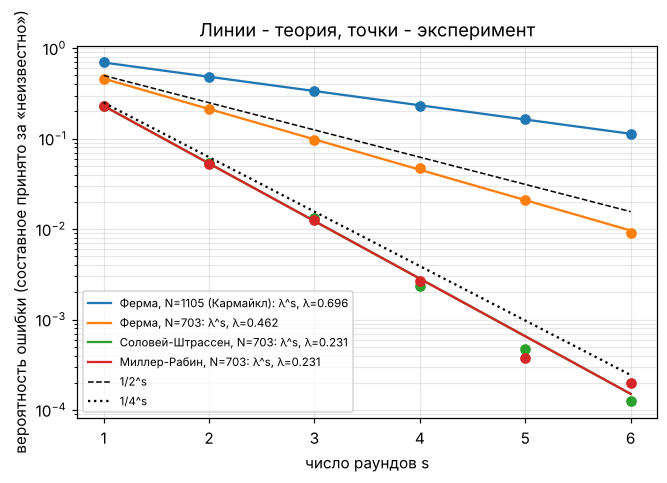

In [11]:
cases = [("Ферма, N=1105 (Кармайкл)", fermat_test, 1105, fermat_round),
         ("Ферма, N=703", fermat_test, 703, fermat_round),
         ("Соловей-Штрассен, N=703", solovay_strassen_test, 703, solovay_strassen_round),
         ("Миллер-Рабин, N=703", miller_rabin_test, 703, miller_rabin_round)]
S = range(1, 7)
trials = 40000
plt.figure(figsize=(6.8, 4.4))
for i, (label, test, N, single) in enumerate(cases):
    lam = len(liars(N, single)) / (N - 1)
    rnd = random.Random(10 + i)
    emp = [sum(test(N, s, rnd) for _ in range(trials)) / trials for s in S]
    plt.semilogy(S, [lam ** s for s in S], "-", color=f"C{i}", label=f"{label}: λ^s, λ={lam:.3f}")
    plt.semilogy([s for s, e in zip(S, emp) if e > 0], [e for e in emp if e > 0], "o", color=f"C{i}")
plt.semilogy(S, [0.5 ** s for s in S], "k--", lw=1, label="1/2^s")
plt.semilogy(S, [0.25 ** s for s in S], "k:", lw=1.5, label="1/4^s")
plt.xlabel("число раундов s"); plt.ylabel("вероятность ошибки (составное принято за «неизвестно»)")
plt.title("Линии - теория, точки - эксперимент"); plt.legend(fontsize=7.5); plt.grid(alpha=.3, which="both")
plt.show()

## 9. Сложность одного раунда
Один раунд каждого теста — $O(\log^3 N)$ (одно возведение в степень по модулю $N$). Замеры на простых числах Мерсенна (для простого $N$ тест всегда выполняет полный раунд).

  127 бит: Ферма    0.049 мс, Соловей-Штрассен    0.068 мс, Миллер-Рабин    0.037 мс
  521 бит: Ферма    0.789 мс, Соловей-Штрассен    0.963 мс, Миллер-Рабин    0.815 мс
 1279 бит: Ферма    8.363 мс, Соловей-Штрассен    8.199 мс, Миллер-Рабин    8.679 мс
 2281 бит: Ферма   54.688 мс, Соловей-Штрассен   49.282 мс, Миллер-Рабин   46.596 мс
 4253 бит: Ферма  229.519 мс, Соловей-Штрассен  224.733 мс, Миллер-Рабин  242.104 мс


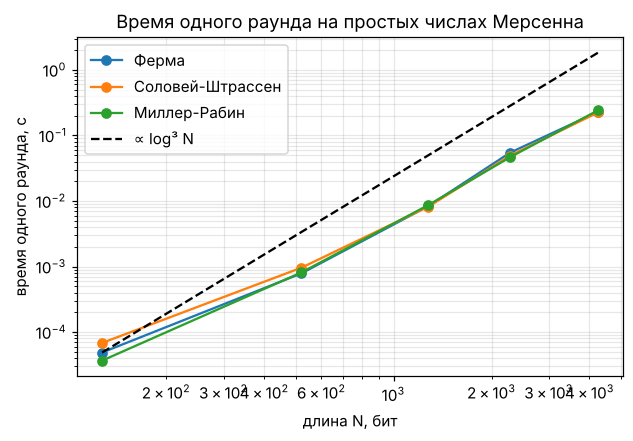

In [12]:
exps = [127, 521, 1279, 2281, 4253]
res = {"Ферма": [], "Соловей-Штрассен": [], "Миллер-Рабин": []}
rnd = random.Random(5)
for k in exps:
    N = 2**k - 1
    reps = 40 if k <= 521 else 8
    bases = [rnd.randrange(2, N - 1) for _ in range(reps)]
    for name, single in (("Ферма", fermat_round), ("Соловей-Штрассен", solovay_strassen_round),
                         ("Миллер-Рабин", miller_rabin_round)):
        t = time.perf_counter()
        for a in bases:
            assert single(N, a)
        res[name].append((time.perf_counter() - t) / reps)

plt.figure(figsize=(6.4, 4))
for name, ts in res.items():
    plt.loglog(exps, ts, "o-", label=name)
plt.loglog(exps, [res["Ферма"][0] * (e / exps[0]) ** 3 for e in exps], "k--", label="∝ log³ N")
plt.xlabel("длина N, бит"); plt.ylabel("время одного раунда, с")
plt.title("Время одного раунда на простых числах Мерсенна"); plt.legend(); plt.grid(alpha=.3, which="both")
plt.show()
for i, k in enumerate(exps):
    print(f"{k:5d} бит: " + ", ".join(f"{n} {ts[i] * 1000:8.3f} мс" for n, ts in res.items()))

## Вывод

* Все три теста принимают любое простое число на любом основании, а составное число объявляют составным, как только найден свидетель. С ростом числа раундов ошибки исчезают.
* Тест Ферма уязвим для чисел Кармайкла: на большом числе Кармайкла он практически не видит составность, тогда как Соловей — Штрассен находит свидетеля примерно в каждом втором раунде (теория: не менее $1/2$), а Миллер — Рабин — не реже чем в трёх раундах из четырёх.
* Доли «лжецов» на малых числах согласуются с теорией: не более половины для Соловея — Штрассена и четверти для Миллера — Рабина (кроме $N=9$); граница $1/4$ достигается.
* Эйлеровы лжецы — подмножество лжецов Ферма, а сильные лжецы — подмножество эйлеровых, поэтому тест Миллера — Рабина самый сильный из трёх при той же трудоёмкости $O(\log^3 N)$ за раунд.